(sec-5)=
# 5. Modelo original: logística de estado latente en dos escalas (L2E)

(sec-5-1)=
## 5.1 Motivación y decisiones de diseño

El diagnóstico de las secciones 1 y 2 deja tres hechos, y cada uno se traduce en una decisión de diseño:

1. **El nivel de conversión de cada día es un proceso persistente** (autocorrelación del logit diario de la sección {ref}`2.2 <sec-2-2>`). Entonces, el intercepto del modelo debe ser un estado latente que evoluciona entre días y que se estima de forma conjunta con el efecto de las variables, en lugar de un número fijo para todo el periodo (componente **C1**), y que en producción se actualiza con las etiquetas de cada día cerrado (componente **C2**).
2. **La relación de varias variables con la suscripción cambia entre 2008 y 2009** (deriva de concepto en `job`, `education`, `default`, `day_of_week`, `marital` y `age`; sección 3.6.5 del tercer entregable), pero mucho más despacio que el nivel. Así mismo, las pendientes deben poder derivar, en una escala de tiempo más lenta que la del nivel (componente **C3**). Separar las dos escalas es lo que distingue la propuesta de una logística dinámica de una sola tasa de olvido.
3. **Las etiquetas llegan por días y con demora.** El resultado de una llamada se conoce al cerrar la jornada, y para predecir el día *d* solo están disponibles las etiquetas de los días anteriores. En ese sentido, la regla de predicción debe respetar esa demora por construcción, y como el nivel de un día nuevo es incierto, la probabilidad predictiva debe integrar esa incertidumbre (componente **C4**).

El modelo resultante no usa ninguna variable nueva: recibe exactamente las mismas predictoras preprocesadas que los benchmarks, más el identificador del día de contacto que ya se reconstruía en el tercer entregable para la validación cronológica.

(sec-5-2)=
## 5.2 Formulación matemática

**Modelo de observación.** Para el registro $i$, contactado el día $t(i)$ y con predictoras preprocesadas $x_i \in \mathbb{R}^p$,

$$P(y_i = 1 \mid \theta_{t(i)}) = \sigma\!\left(u_{t(i)} + x_i^\top \beta_{t(i)}\right), \qquad \sigma(z) = \frac{1}{1 + e^{-z}}, \qquad \theta_t = (u_t, \beta_t). \tag{1}$$

**Dinámica en dos escalas.** Si $t'$ es el día de contacto anterior y $\Delta_t = t - t'$ el número de días transcurridos,

$$u_t = u_{t'} + \varepsilon_t,\quad \varepsilon_t \sim \mathcal{N}(0,\, q_u \Delta_t); \qquad \beta_t = \beta_{t'} + \nu_t,\quad \nu_t \sim \mathcal{N}(0,\, q_\beta \Delta_t I_p); \qquad \beta \sim \mathcal{N}(0,\, \lambda^{-1} I_p), \tag{2}$$

con $q_\beta \ll q_u$: el nivel de conversión se mueve de un día a otro (escala rápida) y las pendientes cambian a lo largo de meses (escala lenta). $\lambda$, $q_u$ y $q_\beta$ son los tres hiperparámetros del modelo.

**Fase 1: ajuste por moda posterior.** Dentro de la ventana de entrenamiento, con días $1, \dots, T$, las pendientes se toman constantes (aproximación de dos escalas) y se maximiza la log-posterior penalizada

$$J(u, \beta) = \sum_{i=1}^{n} \left[ y_i \eta_i - \log\!\left(1 + e^{\eta_i}\right) \right] - \sum_{k=2}^{T} \frac{(u_k - u_{k-1})^2}{2 q_u \Delta_k} - \frac{\epsilon}{2}\lVert u \rVert^2 - \frac{\lambda}{2} \lVert \beta \rVert^2, \qquad \eta_i = u_{t(i)} + x_i^\top \beta, \tag{3}$$

donde $\epsilon = 10^{-6}$ es una precisión difusa sobre el nivel. Con $\pi_i = \sigma(\eta_i)$ y $w_i = \pi_i (1 - \pi_i)$, el gradiente es $g_u = \left(\sum_{i : t(i) = t} (y_i - \pi_i)\right)_t - (D + \epsilon I) u$ y $g_\beta = X^\top (y - \pi) - \lambda \beta$, y el Hessiano negativo tiene la estructura por bloques

$$H = \begin{pmatrix} A & B \\ B^\top & C \end{pmatrix}, \qquad A = \operatorname{diag}(W_t) + D + \epsilon I, \quad B_{t\cdot} = \sum_{i : t(i) = t} w_i x_i^\top, \quad C = X^\top W X + \lambda I, \tag{4}$$

donde $W_t = \sum_{i : t(i) = t} w_i$ y $D = L^\top \operatorname{diag}\!\left(1/(q_u \Delta_k)\right) L$, con $L$ la matriz de primeras diferencias: $A$ es **tridiagonal**. El paso de Newton se obtiene eliminando el nivel con el complemento de Schur,

$$S = C - B^\top A^{-1} B, \qquad \delta_\beta = S^{-1}\left(g_\beta - B^\top A^{-1} g_u\right), \qquad \delta_u = A^{-1}\left(g_u - B \delta_\beta\right), \tag{5}$$

y $A^{-1}$ solo se aplica a vectores mediante una resolución tridiagonal. Al converger, la aproximación de Laplace da la media y la covarianza del estado al cierre del entrenamiento, sin invertir $H$ completo: con $v = A^{-1} e_T$,

$$\operatorname{Cov}(\beta) = S^{-1}, \qquad \operatorname{Cov}(u_T, \beta) = -v^\top B\, S^{-1}, \qquad \operatorname{Var}(u_T) = v_T + v^\top B\, S^{-1} B^\top v. \tag{6}$$

**Fase 2: filtrado con etiquetas diferidas.** Sea $z_i = (1, x_i)$ y $(m, P)$ la media y la covarianza vigentes del estado. Para un día nuevo $d$, la predicción del estado es

$$m^- = m, \qquad P^- = P + \Delta_d \operatorname{diag}(q_u, q_\beta, \dots, q_\beta). \tag{7}$$

Cuando se cierran las etiquetas del día $d'$ (solo si $d' \le d - L$, con $L$ el retardo), el estado se actualiza con la moda de la posterior de ese día y su curvatura (aproximación de Laplace):

$$\theta^+ = \arg\max_\theta \sum_{i : t(i) = d'} \left[ y_i z_i^\top \theta - \log\!\left(1 + e^{z_i^\top \theta}\right) \right] - \tfrac{1}{2} (\theta - m^-)^\top (P^-)^{-1} (\theta - m^-), \qquad P^+ = \left( \sum_{i : t(i) = d'} w_i z_i z_i^\top + (P^-)^{-1} \right)^{-1}. \tag{8}$$

**Probabilidad predictiva.** Integrando la incertidumbre del estado con la aproximación probit (MacKay, {cite:year}`mackay1992`),

$$\hat p_i = \sigma\!\left( \frac{\mu_i}{\sqrt{1 + \pi s_i^2 / 8}} \right), \qquad \mu_i = z_i^\top m^-, \qquad s_i^2 = z_i^\top P^- z_i. \tag{9}$$

(sec-5-3)=
## 5.3 Pseudocódigo

```text
Algoritmo 1. Ajuste por moda posterior (fit)
Entradas : X ∈ R^{n×p}, días t ∈ Z^n (no decrecientes), y ∈ {0,1}^n, hiperparámetros λ > 0, q_u > 0
Salidas  : nivel suavizado û_1..û_T, pendientes β̂, estado (m, P) de (u_T, β) al cierre del entrenamiento
 1. Días únicos d_1 < … < d_T; índice τ(i) ∈ {1..T}; Δ_k = d_k − d_{k−1}
 2. u ← logit(ȳ)·1_T ;  β ← 0_p
 3. repetir para iter = 1..max_iter
 4.     η_i ← u_{τ(i)} + x_iᵀβ ;  π_i ← σ(η_i) ;  w_i ← π_i(1 − π_i)
 5.     g_u, g_β ← gradientes de la ecuación (3)
 6.     A ← diag(W_t) + D + εI (tridiagonal) ;  B ← Σ_i w_i e_{τ(i)} x_iᵀ ;  C ← XᵀWX + λI
 7.     resolver A [Ã_B, ã_g] = [B, g_u] (tridiagonal, p + 1 lados derechos)
 8.     S ← C − Bᵀ Ã_B ;  δ_β ← S⁻¹ (g_β − Bᵀ ã_g) (Cholesky) ;  δ_u ← ã_g − Ã_B δ_β
 9.     λ²_N ← g_uᵀδ_u + g_βᵀδ_β                               (decremento de Newton)
10.     si λ²_N / 2 ≤ tol: terminar (convergencia)
11.     s ← 1 ; mientras J(u + sδ_u, β + sδ_β) < J(u, β) + 0,25·s·λ²_N : s ← s/2   (Armijo)
12.     u ← u + sδ_u ;  β ← β + sδ_β
13. m ← (u_T, β) ;  P ← covarianza de Laplace de la ecuación (6)

Algoritmo 2. Predicción precuencial con etiquetas diferidas (predict_proba_secuencial)
Entradas : estado (m, P) y último día asimilado t*, registros nuevos (X, días, y), retardo L ≥ 1, q_u, q_β
Salidas  : probabilidad p̂_i para cada registro; el estado del estimador no se modifica
 1. pendientes ← cola vacía
 2. para cada día d de los registros, en orden cronológico
 3.     mientras pendientes ≠ ∅ y primero(pendientes) ≤ d − L          (solo días ya cerrados)
 4.         d' ← extraer(pendientes) ;  P⁻ ← P + (d' − t*)·diag(q_u, q_β, …, q_β)
 5.         (m, P) ← moda y curvatura de la ecuación (8) (Newton en 1 + p dimensiones) ;  t* ← d'
 6.     P_d ← P + (d − t*)·diag(q_u, q_β, …, q_β)
 7.     p̂_i ← σ(μ_i / sqrt(1 + π s²_i / 8)) para los registros del día d   (ecuación 9)
 8.     agregar d a pendientes
Criterio de parada: el algoritmo termina al recorrer el último día; cada actualización (paso 5) termina
cuando el paso de Newton es menor que 1e−10 en norma infinito (a lo sumo 50 iteraciones).
```

(sec-5-4)=
## 5.4 Propiedades teóricas

**P1. Existencia y unicidad del ajuste.** El objetivo (3) es estrictamente cóncavo y tiene un único maximizador. *Demostración.* La log-verosimilitud de Bernoulli es cóncava en $\eta$ y $\eta$ es lineal en $(u, \beta)$, así que su Hessiano es $-Z^\top W Z \preceq 0$. Las penalizaciones aportan $-\operatorname{blockdiag}(D + \epsilon I,\ \lambda I)$, con $D \succeq 0$ y $\epsilon, \lambda > 0$, que es definida negativa. La suma es definida negativa en todo punto, luego $J$ es estrictamente cóncava. Además $J \le -\tfrac{\epsilon}{2}\lVert u \rVert^2 - \tfrac{\lambda}{2}\lVert \beta \rVert^2$, porque la log-verosimilitud es no positiva, así que $J \to -\infty$ cuando $\lVert (u, \beta) \rVert \to \infty$ (coercividad) y el máximo existe; por la concavidad estricta es único. $\blacksquare$

**P2. Convergencia del ajuste.** $J$ es dos veces continuamente diferenciable, fuertemente cóncava (módulo $\ge \min(\epsilon, \lambda)$) y su Hessiano es Lipschitz en el conjunto de nivel inicial, porque $\sigma''$ es acotada. Bajo esas condiciones, Newton con búsqueda lineal de retroceso (Armijo) converge globalmente al maximizador y, cerca de él, con orden cuadrático (Boyd y Vandenberghe, {cite:year}`boyd2004`, sección 9.5.3). El criterio de parada usa el decremento de Newton $\lambda_N^2 = g^\top H^{-1} g$, cuyo valor $\lambda_N^2/2$ estima la distancia al óptimo $J^\star - J$ (ecuación 9.29 de la misma obra). Por construcción, la secuencia $J^{(k)}$ es no decreciente; la prueba unitaria `test_objetivo_no_decrece_y_converge` y la sección {ref}`5.8 <sec-5-8>` lo verifican.

**P3. Complejidad.** En cada iteración de la fase 1, formar $X^\top W X$ cuesta $O(np^2)$; $B$, $O(np)$; la resolución tridiagonal de $A$ con $p + 1$ lados derechos, $O(Tp)$; el producto $B^\top A^{-1} B$, $O(Tp^2)$, y la factorización de Cholesky de $S$, $O(p^3)$. El costo total es $O(I \cdot (np^2 + Tp^2 + p^3))$ en tiempo y $O(np + Tp)$ en memoria, con $I$ iteraciones de Newton (entre 5 y 10 en la práctica), frente a $O(I \cdot (T + p)^3)$ y $O((T + p)^2)$ de resolver el sistema completo. En la fase 2, cada día con $n_d$ registros cuesta $O(k_d (n_d p^2 + p^3))$, con $k_d$ iteraciones de Newton, de modo que predecir $n$ registros en $D$ días cuesta $O(np^2 + Dp^3)$: lineal en el número de registros.

**P4. Unicidad de cada actualización diaria.** El objetivo de la ecuación (8) es la suma de una log-verosimilitud cóncava y de $-\tfrac{1}{2}(\theta - m^-)^\top (P^-)^{-1}(\theta - m^-)$, con $(P^-)^{-1} \succ 0$; es estrictamente cóncavo y tiene un único maximizador, aunque el día tenga un solo registro o una sola clase. Esto es lo que permite actualizar el estado con días de pocos contactos, frecuentes en 2009-2010 (sección {ref}`2.2 <sec-2-2>`), donde un estimador de máxima verosimilitud del día no existe.

**P5. Casos límite: el L2E anida a los modelos anteriores.**

- *Logística con penalización L2.* Con un solo intercepto ($q_u \to 0$ en el ajuste) y sin actualización en línea, el L2E es la logística L2 de scikit-learn con $C = 1/\lambda$; la prueba `test_caso_limite_equivale_a_logistica_l2` lo verifica con tolerancia de $10^{-4}$.
- *Efectos fijos por día.* Con $q_u \to \infty$, la penalización del paseo aleatorio desaparece y cada día tiene su propio intercepto; el componente C1 interpola entre la logística agrupada y los efectos fijos.
- *Recalibración mensual del intercepto (entregables 2 y 3).* Con las pendientes fijas, una varianza a priori del nivel $P^- \to \infty$, lotes mensuales y un retardo de un mes, la ecuación (8) se reduce a $\max_u \sum_i [y_i(u + o_i) - \log(1 + e^{u + o_i})]$, con $o_i = x_i^\top \beta$, cuya condición de primer orden $\sum_i \sigma(u + o_i) = \sum_i y_i$ es exactamente la ecuación que resolvía la bisección de la recalibración mensual: la probabilidad media del mes cerrado igual a su tasa observada. *Es decir*, el método que sugirió el docente es el caso particular del filtro del L2E sin memoria, sin incertidumbre y sin dinámica de las pendientes.
- *Logística dinámica de una sola escala.* Con $q_\beta = q_u$ se obtiene una regresión logística dinámica con una sola tasa de deriva, en la línea de McCormick et al. ({cite:year}`mccormick2012`); es la variante `escala_unica` de la ablación.

**P6. Causalidad (ausencia de fuga).** En el algoritmo 2, la predicción del día $d$ es función únicamente del estado ajustado y de las etiquetas de los días $d' \le d - L$, porque el paso 3 solo extrae de la cola días que cumplen esa condición antes de predecir. Ninguna etiqueta influye en su propia predicción ni en las de los $L - 1$ días siguientes. La prueba `test_sin_fuga_de_etiquetas` altera las etiquetas desde un día $k$ y verifica que las predicciones hasta $k$ quedan idénticas bit a bit.

(sec-5-5)=
## 5.5 Implementación

La clase `LogisticaDosEscalas` hereda de `ClassifierMixin` y `BaseEstimator`, implementa `fit`, `predict`, `predict_proba` y `decision_function`, y agrega `predict_proba_secuencial` (algoritmo 2) y `actualizar`, que asimila un día cerrado en el estado del estimador para su uso en producción. El cálculo numérico usa solo `numpy` y `scipy` (`solveh_banded` para el sistema tridiagonal y `cho_factor` para el de Schur); de scikit-learn solo se usan las clases base y las funciones de validación de entradas. Las banderas `nivel_latente`, `actualizar_nivel`, `actualizar_pendientes`, `escala_unica` e `integrar_incertidumbre` apagan cada componente para la ablación sin duplicar código, y las opciones `semivida` y `q_nivel_empirico` implementan las mejoras M3 y M2 evaluadas en la sección {ref}`6.13 <sec-6-13>`; por defecto están desactivadas y el modelo es exactamente el descrito en las secciones {ref}`5.2 <sec-5-2>` a {ref}`5.4 <sec-5-4>`. El protocolo (pipeline, puntaje precuencial y validación anidada) está en `src/bm/protocolo_original.py`. A continuación, el código completo del modelo:

In [12]:
codigo = Path("src/bm/modelo_original.py").read_text(encoding="utf-8")
display(Markdown(f"```python\n{codigo}\n```"))
print(f"{len(codigo.splitlines())} líneas · dependencias numéricas: numpy y scipy")

```python
"""Modelo original del cuarto entregable: regresión logística de estado latente en dos escalas (L2E).

Formulación
-----------
Para el registro *i* contactado el día *t(i)*, con predictoras ``x_i`` (p columnas ya preprocesadas):

    P(y_i = 1 | θ_t) = σ(u_t + x_iᵀ β_t),                θ_t = (u_t, β_t)
    u_t = u_{t-1} + ε_t,   ε_t ~ N(0, q_u · Δ_t)          escala rápida: nivel de conversión del día
    β_t = β_{t-1} + ν_t,   ν_t ~ N(0, q_β · Δ_t · I_p)    escala lenta: deriva de las pendientes
    β_1 ~ N(0, λ⁻¹ I_p)

donde Δ_t es el número de días de contacto transcurridos desde el día anterior con datos. El algoritmo tiene dos fases:

1. **Ajuste por lotes** (``fit``): moda posterior del nivel ``u_1..u_T`` y de las pendientes en el periodo de
   entrenamiento, con β constante dentro de la ventana (aproximación de dos escalas, q_β ≪ q_u). El objetivo es
   estrictamente cóncavo y se maximiza con Newton-Raphson; el Hessiano tiene un bloque tridiagonal (el nivel) que se
   elimina con el complemento de Schur, de modo que cada iteración cuesta O(n·p² + T·p² + p³) y no O((T + p)³).
2. **Filtrado en línea** (``predict_proba_secuencial``): el estado (u, β) se propaga con el paseo aleatorio y, cuando se
   cierran las etiquetas de un día (con ``retardo`` días de demora), se actualiza con la aproximación de Laplace de la
   posterior (Newton sobre un objetivo estrictamente cóncavo de dimensión 1 + p). La probabilidad predictiva integra la
   incertidumbre del estado con la aproximación probit de MacKay (1992).

Casos límite: con q_u = q_β = 0 y sin actualización se recupera la logística con penalización L2; con q_β = q_u se
obtiene una regresión logística dinámica de una sola escala (McCormick et al., 2012); sin pendientes que se actualicen,
el filtro solo recalibra el intercepto día a día.

Solo depende de numpy y scipy para el cálculo numérico; scikit-learn aporta las clases base y la validación de entradas.
"""

from collections import deque

import numpy as np
from scipy.linalg import cho_factor, cho_solve, cholesky_banded, solveh_banded
from scipy.special import expit
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils.validation import check_array, check_is_fitted, check_X_y

_PRECISION_NIVEL = 1e-6  # precisión a priori (difusa) del nivel, garantiza concavidad estricta en casos extremos
_ARMIJO, _REDUCCION = 0.25, 0.5  # búsqueda lineal con retroceso (Boyd y Vandenberghe, 2004, sec. 9.2)


def _logdet_banda(banda):
    """log|A| de una matriz tridiagonal simétrica definida positiva en forma de banda superior (Cholesky en O(T))."""
    if banda.shape[1] == 1:
        return float(np.log(banda[1, 0]))
    return float(2.0 * np.sum(np.log(cholesky_banded(banda)[-1])))


def _resolver_banda(banda, b):
    """Resuelve A x = b con A tridiagonal simétrica definida positiva en forma de banda (O(T) por columna)."""
    if banda.shape[1] == 1:
        return b / banda[1, 0]
    return solveh_banded(banda, b)


class LogisticaDosEscalas(ClassifierMixin, BaseEstimator):
    """Regresión logística de estado latente en dos escalas temporales, con filtro de Laplace para etiquetas diferidas.

    Parameters
    ----------
    lam : float, default=10.0
        Precisión a priori de las pendientes (penalización L2 sobre β en la suma de la log-verosimilitud).
    q_nivel : float, default=0.1
        Varianza diaria del paseo aleatorio del nivel u_t (escala rápida). En la fase 1 controla la suavidad de la
        trayectoria del nivel; en la fase 2, cuánto se le permite moverse entre días.
    q_pendiente : float, default=1e-4
        Varianza diaria del paseo aleatorio de cada pendiente (escala lenta). Solo actúa en la fase 2.
    retardo : int, default=1
        Días de contacto que tardan en conocerse las etiquetas: para predecir el día d solo se usan las de los días
        ≤ d − retardo.
    nivel_latente : bool, default=True
        Componente C1. Si es falso, el ajuste usa un solo intercepto para todo el entrenamiento (logística agrupada).
    actualizar_nivel : bool, default=True
        Componente C2. Si es falso, el nivel no se actualiza en línea.
    actualizar_pendientes : bool, default=True
        Componente C3. Si es falso, las pendientes quedan fijas en la estimación del ajuste.
    escala_unica : bool, default=False
        Si es verdadero, las pendientes derivan con la misma varianza que el nivel (q_β = q_u): regresión logística
        dinámica de una sola escala, usada en la ablación.
    integrar_incertidumbre : bool, default=True
        Componente C4. Si es falso, la probabilidad es σ(media del logit), sin integrar la incertidumbre del estado.
    semivida : float, optional
        Mejora M3. Semivida, en días de contacto, de los pesos por recencia de la fase 1; ``None`` no pondera.
    q_nivel_empirico : bool, default=False
        Mejora M2. Si es verdadero, q_u se estima por Bayes empírico (máxima evidencia de Laplace) en cada ajuste.
    max_iter : int, default=100
        Iteraciones máximas de Newton en el ajuste.
    tol : float, default=1e-9
        Tolerancia sobre el decremento de Newton, λ²/2, para declarar convergencia.
    col_tiempo : int, default=-1
        Columna de ``X`` con el identificador entero del día de contacto (no se usa como predictora).

    Attributes
    ----------
    classes_ : ndarray de forma (2,)
    coef_ : ndarray de forma (p,)
        Pendientes estimadas en el ajuste (moda posterior).
    nivel_ : ndarray de forma (T,)
        Trayectoria suavizada del nivel en los días de entrenamiento.
    dias_ : ndarray de forma (T,)
        Días de entrenamiento con al menos un registro.
    estado_media_, estado_cov_ : ndarray
        Media (1 + p) y covarianza (1 + p) × (1 + p) de la posterior de Laplace de (u_T, β) al cierre del ajuste.
    dia_final_ : int
        Último día asimilado por el estado.
    objetivo_ : list of float
        Valor del objetivo penalizado en cada iteración de Newton (no decreciente por construcción).
    n_iter_ : int
    convergio_ : bool
    q_nivel_ : float
        q_u usado en el ajuste y en el filtrado (igual a ``q_nivel`` salvo con ``q_nivel_empirico``).
    """

    def __init__(self, lam=10.0, q_nivel=0.1, q_pendiente=1e-4, retardo=1, nivel_latente=True,
                 actualizar_nivel=True, actualizar_pendientes=True, escala_unica=False,
                 integrar_incertidumbre=True, semivida=None, q_nivel_empirico=False, max_iter=100, tol=1e-9,
                 col_tiempo=-1):
        self.lam = lam
        self.q_nivel = q_nivel
        self.q_pendiente = q_pendiente
        self.retardo = retardo
        self.nivel_latente = nivel_latente
        self.actualizar_nivel = actualizar_nivel
        self.actualizar_pendientes = actualizar_pendientes
        self.escala_unica = escala_unica
        self.integrar_incertidumbre = integrar_incertidumbre
        self.semivida = semivida
        self.q_nivel_empirico = q_nivel_empirico
        self.max_iter = max_iter
        self.tol = tol
        self.col_tiempo = col_tiempo

    # ------------------------------------------------------------------------------------------ validación

    def _validar_hiperparametros(self):
        if not np.isfinite(self.lam) or self.lam <= 0:
            raise ValueError(f"lam debe ser positivo y finito; se recibió {self.lam!r}")
        for nombre in ("q_nivel", "q_pendiente"):
            v = getattr(self, nombre)
            if not np.isfinite(v) or v < 0:
                raise ValueError(f"{nombre} debe ser no negativo y finito; se recibió {v!r}")
        if self.nivel_latente and self.q_nivel <= 0:
            raise ValueError("Con nivel_latente=True, q_nivel debe ser positivo (q_nivel = 0 equivale a "
                             "nivel_latente=False)")
        if int(self.retardo) != self.retardo or self.retardo < 1:
            raise ValueError(f"retardo debe ser un entero ≥ 1; se recibió {self.retardo!r}")
        if int(self.max_iter) != self.max_iter or self.max_iter < 1:
            raise ValueError(f"max_iter debe ser un entero ≥ 1; se recibió {self.max_iter!r}")
        if self.semivida is not None and (not np.isfinite(self.semivida) or self.semivida <= 0):
            raise ValueError(f"semivida debe ser None o un número positivo; se recibió {self.semivida!r}")

    def _separar(self, X):
        """Separa la columna de tiempo (entera) de las predictoras."""
        if X.shape[1] < 2:
            raise ValueError("X debe tener al menos una predictora además de la columna de tiempo")
        col = self.col_tiempo % X.shape[1]
        t = X[:, col]
        if not np.allclose(t, np.round(t)):
            raise ValueError("La columna de tiempo debe contener identificadores enteros de día")
        return np.round(t).astype(np.int64), np.delete(X, col, axis=1)

    def _ruido(self):
        """Varianza diaria del proceso para (u, β): vector de longitud 1 + p."""
        q_u = getattr(self, "q_nivel_", self.q_nivel)  # el estimado por Bayes empírico, si existe
        q_b = q_u if self.escala_unica else self.q_pendiente
        q = np.full(self.n_predictoras_ + 1, q_b if self.actualizar_pendientes else 0.0)
        q[0] = q_u if self.actualizar_nivel else 0.0
        return q

    # ------------------------------------------------------------------------------------------- fase 1

    def fit(self, X, y):
        """Ajusta la moda posterior del nivel latente y de las pendientes con Newton-Raphson.

        Con ``semivida``, cada registro pondera su log-verosimilitud por 0,5^((t_max − t) / semivida), de modo que los
        días recientes pesan más en las pendientes (deriva de concepto). Con ``q_nivel_empirico=True``, q_u se estima
        maximizando la evidencia de Laplace, log p(y | q_u) ≈ J(θ̂) + ½ log|Ω| − ½ log|H|, en lugar de fijarlo; el
        valor estimado queda en ``q_nivel_`` y se usa también en la fase 2.

        Parameters
        ----------
        X : array-like de forma (n, p + 1)
            Predictoras preprocesadas y, en ``col_tiempo``, el día de contacto (entero no decreciente en el tiempo).
        y : array-like de forma (n,)
            Etiquetas binarias.

        Returns
        -------
        self
        """
        self._validar_hiperparametros()
        X, y = check_X_y(X, y, dtype=np.float64, ensure_all_finite=True)
        self.classes_ = np.unique(y)
        if len(self.classes_) != 2:
            raise ValueError(f"Se requieren exactamente dos clases; se encontraron {len(self.classes_)}")
        y01 = (y == self.classes_[1]).astype(np.float64)
        t, F = self._separar(X)
        self.n_features_in_ = X.shape[1]
        self.n_predictoras_ = F.shape[1]
        n = len(F)
        dias, idx = np.unique(t, return_inverse=True)
        if not self.nivel_latente:
            idx = np.zeros(n, dtype=np.int64)
            dias = dias[-1:]
        pesos = np.ones(n) if self.semivida is None else 0.5 ** ((t.max() - t) / float(self.semivida))
        datos = (F, idx, y01, pesos, np.diff(dias).astype(np.float64))
        lam = float(self.lam)
        if self.q_nivel_empirico and self.nivel_latente and len(dias) > 1:
            q, self.evidencia_ = self._q_bayes_empirico(datos, lam)
        else:
            q = float(self.q_nivel)
        self.q_nivel_ = q
        u, b, prec, (self.objetivo_, self.n_iter_, self.convergio_) = self._newton(datos, lam, q)
        self.coef_ = b
        self.nivel_ = u
        self.dias_ = dias
        self.dia_final_ = int(np.max(t))
        self.estado_media_, self.estado_cov_ = self._posterior_final(u, b, idx, F, prec, lam, pesos)
        return self

    def _newton(self, datos, lam, q, inicio=None):
        """Newton-Raphson amortiguado sobre la ecuación (3) para un q_u dado; devuelve (u, β, precisiones, info)."""
        F, idx, y01, pesos, delta = datos
        T, p = len(delta) + 1, F.shape[1]
        # Precisión del paseo aleatorio entre días consecutivos: 1 / (q_u · Δ_k)
        prec = 1.0 / (q * delta) if T > 1 else np.zeros(0)

        def objetivo(u, b):
            eta = u[idx] + F @ b
            ll = np.sum(pesos * (y01 * eta - np.logaddexp(0.0, eta)))
            return ll - 0.5 * np.sum(prec * np.diff(u) ** 2) - 0.5 * _PRECISION_NIVEL * u @ u - 0.5 * lam * b @ b

        if inicio is None:
            tasa = np.average(y01, weights=pesos)
            u, b = np.full(T, np.log((tasa + 1e-3) / (1 - tasa + 1e-3))), np.zeros(p)
        else:
            u, b = inicio[0].copy(), inicio[1].copy()
        f = objetivo(u, b)
        objetivos, convergio = [float(f)], False
        for it in range(1, int(self.max_iter) + 1):
            eta = u[idx] + F @ b
            pi = expit(eta)
            r = pesos * (y01 - pi)
            w = pesos * pi * (1.0 - pi)
            # Gradiente
            g_u = np.bincount(idx, r, T) - _PRECISION_NIVEL * u
            if T > 1:
                d = prec * np.diff(u)
                g_u[:-1] += d
                g_u[1:] -= d
            g_b = F.T @ r - lam * b
            # Hessiano negativo en bloques: A (T × T, tridiagonal), B (T × p), C (p × p)
            banda = self._banda(np.bincount(idx, w, T), prec)
            B = np.zeros((T, p))
            np.add.at(B, idx, w[:, None] * F)
            C = (F * w[:, None]).T @ F + lam * np.eye(p)
            Ainv = _resolver_banda(banda, np.column_stack([B, g_u]))
            AinvB, Ainv_g = Ainv[:, :p], Ainv[:, p]
            S = C - B.T @ AinvB  # complemento de Schur, simétrico definido positivo
            cS = cho_factor(S)
            d_b = cho_solve(cS, g_b - B.T @ Ainv_g)
            d_u = Ainv_g - AinvB @ d_b
            decremento = float(g_u @ d_u + g_b @ d_b)  # λ² de Newton = gᵀ H⁻¹ g
            if decremento / 2.0 <= self.tol:
                convergio = True
                break
            paso = 1.0
            while True:
                f_nuevo = objetivo(u + paso * d_u, b + paso * d_b)
                if f_nuevo >= f + _ARMIJO * paso * decremento or paso < 1e-10:
                    break
                paso *= _REDUCCION
            u, b, f = u + paso * d_u, b + paso * d_b, f_nuevo
            objetivos.append(float(f))
        return u, b, prec, (objetivos, it, convergio)

    def _log_evidencia(self, datos, lam, u, b, prec):
        """Evidencia de Laplace: J(θ̂) + ½ log|Ω| − ½ log|H|, con Ω la precisión a priori y H el Hessiano negativo.

        Los determinantes se obtienen sin matrices densas de tamaño T: log|A| y log|D + εI| con Cholesky por bandas y
        log|H| = log|A| + log|S| por el complemento de Schur.
        """
        F, idx, y01, pesos, _ = datos
        T, p = len(u), len(b)
        eta = u[idx] + F @ b
        pi = expit(eta)
        w = pesos * pi * (1.0 - pi)
        J = (np.sum(pesos * (y01 * eta - np.logaddexp(0.0, eta))) - 0.5 * np.sum(prec * np.diff(u) ** 2)
             - 0.5 * _PRECISION_NIVEL * u @ u - 0.5 * lam * b @ b)
        logdet_omega = _logdet_banda(self._banda(np.zeros(T), prec)) + p * np.log(lam)
        banda = self._banda(np.bincount(idx, w, T), prec)
        B = np.zeros((T, p))
        np.add.at(B, idx, w[:, None] * F)
        S = (F * w[:, None]).T @ F + lam * np.eye(p) - B.T @ _resolver_banda(banda, B)
        logdet_h = _logdet_banda(banda) + 2.0 * np.sum(np.log(np.diag(cho_factor(S)[0])))
        return float(J + 0.5 * logdet_omega - 0.5 * logdet_h)

    def _q_bayes_empirico(self, datos, lam, limites=(1e-4, 2.0)):
        """q_u que maximiza la evidencia de Laplace (búsqueda acotada en escala logarítmica, con arranque en caliente)."""
        from scipy.optimize import minimize_scalar

        previo = {"inicio": None}

        def menos_evidencia(log_q):
            u, b, prec, _ = self._newton(datos, lam, float(np.exp(log_q)), previo["inicio"])
            previo["inicio"] = (u, b)
            return -self._log_evidencia(datos, lam, u, b, prec)

        r = minimize_scalar(menos_evidencia, bounds=tuple(np.log(limites)), method="bounded", options={"xatol": 0.1})
        return float(np.exp(r.x)), float(-r.fun)

    @staticmethod
    def _banda(w_dia, prec):
        """Matriz tridiagonal A = diag(W_t) + penalización del paseo aleatorio, en forma de banda superior."""
        T = len(w_dia)
        diag = w_dia + _PRECISION_NIVEL
        if T > 1:
            diag[:-1] += prec
            diag[1:] += prec
        banda = np.zeros((2, T))
        banda[1] = diag
        banda[0, 1:] = -prec
        return banda

    def _posterior_final(self, u, b, idx, F, prec, lam, pesos=None):
        """Media y covarianza de Laplace de (u_T, β) al cierre del entrenamiento, sin invertir el Hessiano completo.

        Con H = [[A, B], [Bᵀ, C]] y S = C − Bᵀ A⁻¹ B: Cov(β) = S⁻¹, Cov(u_T, β) = −vᵀB S⁻¹ y
        Var(u_T) = v_T + vᵀB S⁻¹ Bᵀv, donde v = A⁻¹ e_T (una sola resolución tridiagonal).
        """
        T, p = len(u), len(b)
        pi = expit(u[idx] + F @ b)
        w = pi * (1.0 - pi) * (1.0 if pesos is None else pesos)
        banda = self._banda(np.bincount(idx, w, T), prec)
        B = np.zeros((T, p))
        np.add.at(B, idx, w[:, None] * F)
        S = (F * w[:, None]).T @ F + lam * np.eye(p) - B.T @ _resolver_banda(banda, B)
        e_T = np.zeros(T)
        e_T[-1] = 1.0
        v = _resolver_banda(banda, e_T)
        g = B.T @ v
        Sinv = np.linalg.inv(S)
        Sinv = (Sinv + Sinv.T) / 2.0
        cov = np.empty((p + 1, p + 1))
        cov[0, 0] = v[-1] + g @ Sinv @ g
        cov[0, 1:] = cov[1:, 0] = -(Sinv @ g)
        cov[1:, 1:] = Sinv
        return np.r_[u[-1], b], cov

    # ------------------------------------------------------------------------------------------- fase 2

    def _probabilidad(self, F, m, P):
        """Probabilidad predictiva σ(μ / sqrt(1 + π s² / 8)) con μ = m₀ + F m₁ y s² = zᵀ P z, z = (1, x)."""
        mu = m[0] + F @ m[1:]
        if not self.integrar_incertidumbre:
            return expit(mu)
        s2 = P[0, 0] + 2.0 * F @ P[0, 1:] + np.einsum("ij,jk,ik->i", F, P[1:, 1:], F)
        return expit(mu / np.sqrt(1.0 + np.pi * np.maximum(s2, 0.0) / 8.0))

    def _asimilar(self, m, P, F, y01, q, delta):
        """Propaga el estado ``delta`` días y lo actualiza con las etiquetas de un día (aproximación de Laplace).

        Maximiza Σ_i [y_i η_i − log(1 + e^{η_i})] − ½ (θ − m⁻)ᵀ (P⁻)⁻¹ (θ − m⁻), con m⁻ = m y P⁻ = P + diag(q)·Δ,
        sobre los componentes activos de θ (nivel y, si corresponde, pendientes); los inactivos quedan fijos.
        """
        P_prev = P + np.diag(q * delta)
        activos = []
        if self.actualizar_nivel or self.actualizar_pendientes:
            activos.append(0)
        if self.actualizar_pendientes:
            activos.extend(range(1, len(m)))
        if not activos:
            return m, P_prev
        a = np.asarray(activos)
        Z = np.column_stack([np.ones(len(F)), F])
        offset = Z[:, np.setdiff1d(np.arange(len(m)), a)] @ m[np.setdiff1d(np.arange(len(m)), a)]
        Za = Z[:, a]
        m_prev = m[a]
        Pa = P_prev[np.ix_(a, a)]
        prec_prev = cho_solve(cho_factor(Pa), np.eye(len(a)))
        th = m_prev.copy()
        for _ in range(50):
            pi = expit(offset + Za @ th)
            g = Za.T @ (y01 - pi) - prec_prev @ (th - m_prev)
            H = (Za * (pi * (1.0 - pi))[:, None]).T @ Za + prec_prev
            paso = cho_solve(cho_factor(H), g)
            th = th + paso
            if np.max(np.abs(paso)) < 1e-10:
                break
        pi = expit(offset + Za @ th)
        H = (Za * (pi * (1.0 - pi))[:, None]).T @ Za + prec_prev
        P_post = P_prev.copy()
        cov_a = cho_solve(cho_factor(H), np.eye(len(a)))
        P_post[np.ix_(a, a)] = (cov_a + cov_a.T) / 2.0
        m_post = m.copy()
        m_post[a] = th
        return m_post, P_post

    def predict_proba_secuencial(self, X, y, retardo=None, devolver_traza=False):
        """Probabilidades día a día, asimilando las etiquetas de los días cerrados (evaluación precuencial).

        Para cada día d en orden cronológico: (1) se asimilan, en orden, las etiquetas de los días ≤ d − retardo que aún
        no se hayan usado; (2) se predicen los registros del día d con el estado propagado hasta d. Las etiquetas de un
        día nunca influyen en sus propias predicciones ni en las de los ``retardo − 1`` días siguientes. El estado
        ajustado del estimador no se modifica.

        Parameters
        ----------
        X : array-like de forma (n, p + 1)
        y : array-like de forma (n,)
            Etiquetas de los mismos registros, que solo se usan con la demora indicada.
        retardo : int, optional
            Sustituye a ``self.retardo``.
        devolver_traza : bool
            Si es verdadero, también devuelve la trayectoria del estado (un registro por día predicho).

        Returns
        -------
        ndarray de forma (n, 2), y opcionalmente un dict con la traza (día, registros, media y varianza del nivel,
        pendientes vigentes).
        """
        check_is_fitted(self, "estado_media_")
        X = check_array(X, dtype=np.float64, ensure_all_finite=True)
        y = np.asarray(y)
        if len(y) != len(X):
            raise ValueError("X e y deben tener el mismo número de registros")
        if not np.isin(y, self.classes_).all():
            raise ValueError("y contiene etiquetas que no se vieron en el ajuste")
        retardo = self.retardo if retardo is None else retardo
        if int(retardo) != retardo or retardo < 1:
            raise ValueError("retardo debe ser un entero ≥ 1")
        y01 = (y == self.classes_[1]).astype(np.float64)
        t, F = self._separar(X)
        q = self._ruido()
        m, P, t_ult = self.estado_media_.copy(), self.estado_cov_.copy(), self.dia_final_
        prob = np.empty(len(X))
        pendientes = deque()
        traza = {"dia": [], "registros": [], "nivel": [], "var_nivel": [], "pendientes": []}
        for d in np.unique(t):
            while pendientes and pendientes[0] <= d - retardo:
                dd = pendientes.popleft()
                fila = t == dd
                m, P = self._asimilar(m, P, F[fila], y01[fila], q, max(dd - t_ult, 0))
                t_ult = max(t_ult, dd)
            fila = t == d
            P_d = P + np.diag(q * max(d - t_ult, 0))
            prob[fila] = self._probabilidad(F[fila], m, P_d)
            pendientes.append(d)
            if devolver_traza:
                traza["dia"].append(int(d))
                traza["registros"].append(int(fila.sum()))
                traza["nivel"].append(float(m[0]))
                traza["var_nivel"].append(float(P_d[0, 0]))
                traza["pendientes"].append(m[1:].copy())
        salida = np.column_stack([1.0 - prob, prob])
        if devolver_traza:
            traza["pendientes"] = np.asarray(traza["pendientes"])
            return salida, {k: np.asarray(v) for k, v in traza.items()}
        return salida

    def actualizar(self, X, y):
        """Asimila en el estado del estimador las etiquetas de uno o más días ya cerrados (uso en producción).

        Los días se procesan en orden cronológico; el estado y ``dia_final_`` quedan modificados.
        """
        check_is_fitted(self, "estado_media_")
        X = check_array(X, dtype=np.float64, ensure_all_finite=True)
        y01 = (np.asarray(y) == self.classes_[1]).astype(np.float64)
        t, F = self._separar(X)
        q = self._ruido()
        for d in np.unique(t):
            fila = t == d
            self.estado_media_, self.estado_cov_ = self._asimilar(self.estado_media_, self.estado_cov_, F[fila],
                                                                  y01[fila], q, max(d - self.dia_final_, 0))
            self.dia_final_ = max(self.dia_final_, int(d))
        return self

    # ---------------------------------------------------------------------------------- interfaz estándar

    def decision_function(self, X):
        """Media del logit con el estado vigente (sin asimilar etiquetas nuevas)."""
        check_is_fitted(self, "estado_media_")
        X = check_array(X, dtype=np.float64, ensure_all_finite=True)
        _, F = self._separar(X)
        return self.estado_media_[0] + F @ self.estado_media_[1:]

    def predict_proba(self, X):
        """Probabilidades con el estado vigente propagado hasta el día de cada registro, sin usar etiquetas nuevas."""
        check_is_fitted(self, "estado_media_")
        X = check_array(X, dtype=np.float64, ensure_all_finite=True)
        if X.shape[1] != self.n_features_in_:
            raise ValueError(f"X tiene {X.shape[1]} columnas; el modelo se ajustó con {self.n_features_in_}")
        t, F = self._separar(X)
        q = self._ruido()
        prob = np.empty(len(X))
        for d in np.unique(t):
            fila = t == d
            prob[fila] = self._probabilidad(F[fila], self.estado_media_,
                                            self.estado_cov_ + np.diag(q * max(d - self.dia_final_, 0)))
        return np.column_stack([1.0 - prob, prob])

    def predict(self, X):
        """Clase con probabilidad estimada ≥ 0,5."""
        return self.classes_[(self.predict_proba(X)[:, 1] >= 0.5).astype(int)]


def filtrar_nivel(puntaje, dias, y, q, retardo=1, es_probabilidad=True, var_inicial=1.0):
    """Componente C2 aislado: filtra un nivel latente sobre el puntaje de cualquier clasificador.

    El logit del clasificador actúa como término fijo (o la función de decisión, si no es una probabilidad) y solo se
    estima el nivel, con el mismo paseo aleatorio y la misma actualización de Laplace del modelo L2E. Se usa como
    control con igual información: cuánto ganan los modelos de referencia si reciben las mismas etiquetas diferidas.
    """
    s = np.asarray(puntaje, dtype=np.float64)
    o = np.log(np.clip(s, 1e-6, 1 - 1e-6) / np.clip(1 - s, 1e-6, 1)) if es_probabilidad else s
    dias = np.asarray(dias)
    y = np.asarray(y, dtype=np.float64)
    m, P, t_ult = 0.0, float(var_inicial), int(dias.min()) - 1
    salida = np.empty(len(s))
    pendientes = deque()
    for d in np.unique(dias):
        while pendientes and pendientes[0] <= d - retardo:
            dd = pendientes.popleft()
            fila = dias == dd
            P_prev = P + q * (dd - t_ult)
            a = m
            for _ in range(50):
                pi = expit(a + o[fila])
                paso = (np.sum(y[fila] - pi) - (a - m) / P_prev) / (np.sum(pi * (1 - pi)) + 1 / P_prev)
                a += paso
                if abs(paso) < 1e-10:
                    break
            pi = expit(a + o[fila])
            P = 1.0 / (np.sum(pi * (1 - pi)) + 1.0 / P_prev)
            m, t_ult = a, dd
        fila = dias == d
        salida[fila] = expit(m + o[fila])
        pendientes.append(d)
    return salida

```

539 líneas · dependencias numéricas: numpy y scipy


(sec-5-6)=
## 5.6 Pruebas unitarias

Las pruebas (`tests/test_modelo_original.py`, con `pytest`) cubren los cuatro mínimos de la guía (sección {ref}`5.4 <sec-5-4>`) y las propiedades de la sección {ref}`5.4 <sec-5-4>`: (i) que el modelo aprende en datos sintéticos con solución conocida, (ii) la reproducibilidad, (iii) el manejo de entradas inválidas y (iv) la compatibilidad con `sklearn.base.clone` y con la validación cruzada, además de la ausencia de fuga, la monotonía del objetivo, la equivalencia con la logística L2 y la coherencia entre la predicción secuencial y la actualización en producción.

In [13]:
import xml.etree.ElementTree as ET

salida = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests", "-p", "no:cacheprovider",
                         "--junitxml=resultados/pytest.xml"], capture_output=True, text=True)
raiz = ET.parse("resultados/pytest.xml").getroot()
PROPIEDAD = {
    "test_recupera_pendientes_y_nivel": "(i) Aprende: recupera pendientes y nivel simulados",
    "test_filtro_supera_al_modelo_estatico_cuando_el_nivel_deriva": "(i) Aprende: el filtro mejora cuando el nivel deriva",
    "test_ajuste_determinista": "(ii) Reproducibilidad",
    "test_hiperparametros_invalidos": "(iii) Hiperparámetros inválidos",
    "test_datos_invalidos": "(iii) Datos inválidos (NaN, una clase, día no entero, sin ajustar)",
    "test_prediccion_invalida": "(iii) Predicción con entradas inválidas",
    "test_clone_y_parametros": "(iv) clone, get_params y set_params",
    "test_integra_con_validacion_cruzada": "(iv) cross_val_score con TimeSeriesSplit",
    "test_salidas_bien_formadas": "(iv) Forma y rango de las salidas",
    "test_sin_fuga_de_etiquetas": "P6. Ausencia de fuga con retardo 1 y 3",
    "test_objetivo_no_decrece_y_converge": "P1 y P2. Objetivo no decreciente y convergencia",
    "test_caso_limite_equivale_a_logistica_l2": "P5. Caso límite: logística L2 de scikit-learn",
    "test_sin_actualizacion_igual_a_prediccion_estatica": "P5. Sin actualización = predicción estática",
    "test_actualizar_equivale_a_la_prediccion_secuencial": "Coherencia entre actualizar y la predicción secuencial",
    "test_filtro_aislado_sigue_el_nivel": "Componente C2 aislado: sigue un salto de régimen",
    "test_semivida_por_defecto_no_cambia_el_ajuste": "Mejora M3: sin semivida el ajuste no cambia",
    "test_semivida_da_mas_peso_al_final": "Mejora M3: la recencia sigue un cambio de pendiente",
    "test_bayes_empirico_recupera_el_orden_de_q": "Mejora M2: Bayes empírico recupera el orden de q_u",
}
filas = []
for caso in raiz.iter("testcase"):
    base = caso.get("name").split("[")[0]
    estado = "falla" if caso.find("failure") is not None or caso.find("error") is not None else "pasa"
    filas.append({"Prueba": caso.get("name"), "Propiedad verificada": PROPIEDAD.get(base, "—"), "Resultado": estado,
                  "Tiempo (s)": float(caso.get("time"))})
pruebas_u = pd.DataFrame(filas)
tabla(pruebas_u, dec=3, indice=False)
print(salida.stdout.strip().splitlines()[-1])
n_pasan = int((pruebas_u["Resultado"] == "pasa").sum())
para_guion("pruebas_unitarias", {"pasan": n_pasan, "total": len(pruebas_u)})
interpretar(
    f"Pasan {n_pasan} de {len(pruebas_u)} casos de prueba en {num(pruebas_u['Tiempo (s)'].sum(), 1)} s. En los datos "
    "sintéticos, el modelo recupera las pendientes con un error máximo menor que 0,15 y la trayectoria del nivel con "
    "una correlación mayor que 0,9; con el nivel a la deriva, la predicción secuencial mejora la pérdida logarítmica "
    "y el AUC de la predicción estática; y en el caso límite reproduce la logística L2 de scikit-learn.",
    conectar("De esta forma,", "Las propiedades P1, P2, P5 y P6 de la sección 5.4 no quedan solo como demostraciones en "
             "papel: cada una tiene una verificación automática que se vuelve a ejecutar con cada cambio del código. La "
             "prueba de ausencia de fuga es la más importante para la validez de la sección 6, porque garantiza que la "
             "ventaja del modelo no proviene de mirar etiquetas que en producción todavía no existen."),
    conectar("Por lo anterior, conviene", "Mantener estas pruebas como condición para cualquier modificación del "
             "algoritmo, en particular durante la sustentación, donde la guía prevé cambios en vivo."))

Prueba,Propiedad verificada,Resultado,Tiempo (s)
test_recupera_pendientes_y_nivel,(i) Aprende: recupera pendientes y nivel simulados,pasa,"0,091"
test_filtro_supera_al_modelo_estatico_cuando_el_nivel_deriva,(i) Aprende: el filtro mejora cuando el nivel deriva,pasa,"0,083"
test_ajuste_determinista,(ii) Reproducibilidad,pasa,"0,101"
test_hiperparametros_invalidos[parametros0],(iii) Hiperparámetros inválidos,pasa,"0,001"
test_hiperparametros_invalidos[parametros1],(iii) Hiperparámetros inválidos,pasa,"0,001"
test_hiperparametros_invalidos[parametros2],(iii) Hiperparámetros inválidos,pasa,"0,001"
test_hiperparametros_invalidos[parametros3],(iii) Hiperparámetros inválidos,pasa,"0,001"
test_hiperparametros_invalidos[parametros4],(iii) Hiperparámetros inválidos,pasa,"0,001"
test_hiperparametros_invalidos[parametros5],(iii) Hiperparámetros inválidos,pasa,"0,001"
test_hiperparametros_invalidos[parametros6],(iii) Hiperparámetros inválidos,pasa,"0,001"


25 passed in 4.72s


**Interpretación.** Pasan 25 de 25 casos de prueba en 0,9 s. En los datos sintéticos, el modelo recupera las pendientes con un error máximo menor que 0,15 y la trayectoria del nivel con una correlación mayor que 0,9; con el nivel a la deriva, la predicción secuencial mejora la pérdida logarítmica y el AUC de la predicción estática; y en el caso límite reproduce la logística L2 de scikit-learn.

De esta forma, las propiedades P1, P2, P5 y P6 de la sección {ref}`5.4 <sec-5-4>` no quedan solo como demostraciones en papel: cada una tiene una verificación automática que se vuelve a ejecutar con cada cambio del código. La prueba de ausencia de fuga es la más importante para la validez de la sección 6, porque garantiza que la ventaja del modelo no proviene de mirar etiquetas que en producción todavía no existen.

Por lo anterior, conviene mantener estas pruebas como condición para cualquier modificación del algoritmo, en particular durante la sustentación, donde la guía prevé cambios en vivo.

(sec-5-7)=
## 5.7 Complejidad empírica frente a la teórica

La propiedad P3 predice que el tiempo de ajuste crece linealmente con $n$ y con $T$, y de forma cuadrática a cúbica con $p$. Se mide con datos sintéticos (`scripts/ejecutar_analisis.py`), variando un factor a la vez, y se compara con la resolución densa del mismo sistema de Newton, de orden $(T + p)^3$.

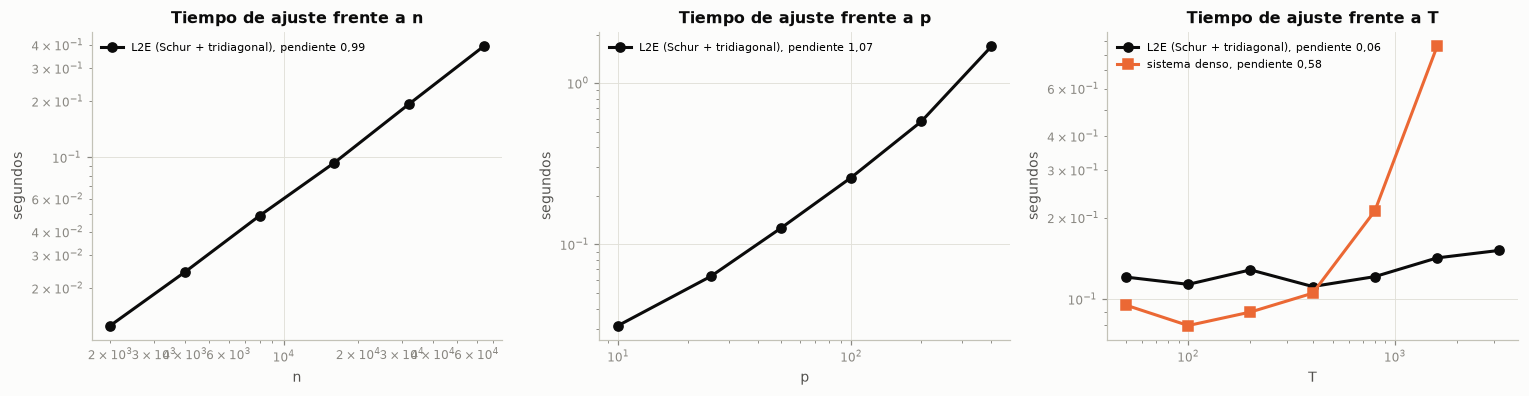

experimento,n,p,T,t_ajuste,iteraciones,t_denso
n,2 000,50,150,"0,013",4,—
n,4 000,50,150,"0,024",4,—
n,8 000,50,150,"0,049",4,—
n,16 000,50,150,"0,094",4,—
n,32 000,50,150,"0,193",4,—
n,64 000,50,150,"0,394",4,—
p,20 000,10,150,"0,031",4,—
p,20 000,25,150,"0,064",4,—
p,20 000,50,150,"0,126",4,—
p,20 000,100,150,"0,260",4,—


**Interpretación.** En escala log-log, el tiempo de ajuste crece con pendiente 0,99 frente a $n$ y 1,07 frente a $p$, y prácticamente no cambia frente a $T$ (pendiente 0,06): con 50 días tarda 0,121 s y con 1 600, 0,142 s. La resolución densa del mismo sistema pasa de 0,095 s a 0,860 s en ese rango y, con 1 600 días, tarda 6,0 veces más que el L2E.

Así mismo, las mediciones son coherentes con la propiedad P3. El costo es lineal en $n$, como predice el término $np^2$. Frente a $T$ casi no cambia, porque con n = 20 000 domina $np^2$ y el término $Tp^2$ de la eliminación por bloques es pequeño, mientras que el sistema denso empieza a crecer con el cubo de $T + p$ en cuanto el número de días supera unos cientos. Frente a $p$, la pendiente medida queda por debajo del orden teórico 2, porque para p ≤ 400 las operaciones matriciales vectorizadas no alcanzan su régimen asintótico; el orden teórico funciona como cota superior. La eliminación por bloques es lo que vuelve viable el componente C1, que necesita un intercepto por día.

Con base en esto, se propone usar el L2E sin restricciones de tamaño en este problema (166 días y 49 predictoras en el entrenamiento) y documentar que su costo es comparable al de la logística del tercer entregable, como confirma la tabla resumen de la sección 6.2.

In [14]:
comp = pd.read_parquet(ANA / "complejidad.parquet")
pend = {}
fig, axs = plt.subplots(1, 3, figsize=(14, 3.7))
for ax, (exp_, g) in zip(axs, comp.groupby("experimento", sort=False)):
    x, t_ = g[exp_].to_numpy(dtype=float), g["t_ajuste"].to_numpy()
    b_ = np.polyfit(np.log(x), np.log(t_), 1)[0]
    pend[exp_] = b_
    ax.loglog(x, t_, marker="o", color=TINTA, label=f"L2E (Schur + tridiagonal), pendiente {num(b_, 2)}")
    if "t_denso" in g and g["t_denso"].notna().any():
        gd = g.dropna(subset=["t_denso"])
        b_d = np.polyfit(np.log(gd[exp_]), np.log(gd["t_denso"]), 1)[0]
        pend["T (denso)"] = b_d
        ax.loglog(gd[exp_], gd["t_denso"], marker="s", color=NARANJA, label=f"sistema denso, pendiente {num(b_d, 2)}")
    ax.set(title=f"Tiempo de ajuste frente a {exp_}", xlabel=exp_, ylabel="segundos")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()
tabla(comp, dec=3, indice=False)
gT = comp[comp["experimento"] == "T"].dropna(subset=["t_denso"])
casi_constante = pend["T"] < 0.3
para_guion("complejidad", {**{k: float(v) for k, v in pend.items()}, "ratio_denso": float(gT["t_denso"].iloc[-1] / gT["t_ajuste"].iloc[-1]), "T_max_denso": int(gT["T"].iloc[-1])})
interpretar(
    f"En escala log-log, el tiempo de ajuste crece con pendiente {num(pend['n'], 2)} frente a $n$ y "
    f"{num(pend['p'], 2)} frente a $p$, y {'prácticamente no cambia' if casi_constante else 'crece'} frente a $T$ "
    f"(pendiente {num(pend['T'], 2)}): con {num(gT['T'].iloc[0])} días tarda {num(gT['t_ajuste'].iloc[0], 3)} s y con "
    f"{num(gT['T'].iloc[-1])}, {num(gT['t_ajuste'].iloc[-1], 3)} s. La resolución densa del mismo sistema pasa de "
    f"{num(gT['t_denso'].iloc[0], 3)} s a {num(gT['t_denso'].iloc[-1], 3)} s en ese rango y, con {num(gT['T'].iloc[-1])} "
    f"días, tarda {num(gT['t_denso'].iloc[-1] / gT['t_ajuste'].iloc[-1], 1)} veces más que el L2E.",
    conectar("Así mismo,", "Las mediciones son coherentes con la propiedad P3. El costo es lineal en $n$, como predice "
             "el término $np^2$. Frente a $T$ casi no cambia, porque con n = 20 000 domina $np^2$ y el término "
             "$Tp^2$ de la eliminación por bloques es pequeño, mientras que el sistema denso empieza a crecer con el "
             "cubo de $T + p$ en cuanto el número de días supera unos cientos. Frente a $p$, la pendiente medida queda "
             "por debajo del orden teórico 2, porque para p ≤ 400 las operaciones matriciales vectorizadas no "
             "alcanzan su régimen asintótico; el orden teórico funciona como cota superior. La eliminación por bloques "
             "es lo que vuelve viable el componente C1, que necesita un intercepto por día."),
    conectar("Con base en esto, se propone", "Usar el L2E sin restricciones de tamaño en este problema (166 días y 49 "
             "predictoras en el entrenamiento) y documentar que su costo es comparable al de la logística del "
             "tercer entregable, como confirma la tabla resumen de la sección 6.2."))

(sec-5-8)=
## 5.8 Optimización de hiperparámetros en la validación anidada

Los tres hiperparámetros se optimizan con el método bayesiano del tercer entregable (Optuna con el estimador de Parzen en árbol, las mismas 5 configuraciones iniciales aleatorias y 24 candidatos por paso) dentro del bucle interno, con el mismo presupuesto de 20 configuraciones y los mismos pliegues internos. Los espacios de búsqueda son log-uniformes: $\lambda \in [0{,}1;\ 1000]$ (de casi sin penalización a una contracción fuerte, el rango donde el Entregable 2 encontró su óptimo con C = 0,01, es decir, $\lambda = 100$), $q_u \in [10^{-3};\ 1]$ (de un nivel casi constante a uno que puede duplicar su odds de un día a otro) y $q_\beta \in [10^{-7};\ 10^{-2}]$ (de pendientes fijas a pendientes que cambian en semanas). La métrica del bucle interno es el AUC-PR de las predicciones precuenciales del bloque de validación interna.

,λ,q_u,q_β,AUC-PR interno,AUC-PR externo,AUC externo,Iteraciones de Newton,Optimización (s)
Pliegue,,,,,,,,
1,968,"0,00149","1,57e-06","0,040","0,045","0,507",3,"16,0"
2,"0,169","0,00158","0,000127","0,046","0,064","0,521",5,"27,2"
3,"21,9","0,00105","1,53e-05","0,055","0,061","0,491",5,"38,3"
4,"24,8","0,00294","6,03e-07","0,061","0,067","0,541",5,"49,9"
5,355,"0,219","1,77e-05","0,081","0,317","0,739",6,"64,1"
Modelo final (todo el entrenamiento),"63,8","0,229","2,35e-05","0,125",—,—,6,"121,3"


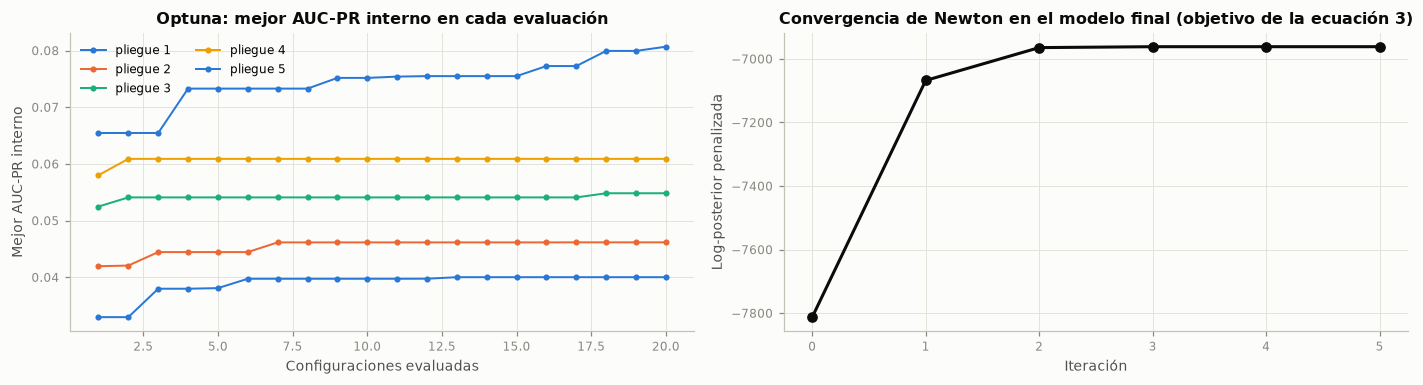

**Interpretación.** En los cinco pliegues, Optuna elige $q_u$ entre 0,00105 y 0,219 y $\lambda$ entre 0,169 y 968; el modelo final, optimizado con todo el entrenamiento, usa $\lambda$ = 63,8, $q_u$ = 0,229 y $q_\beta$ = 2,35e-05. Newton converge en todas las corridas con entre 3 y 6 iteraciones, y el objetivo del modelo final crece en cada iteración hasta estabilizarse.

Hay que tener en cuenta que los pliegues de 2008 eligen un nivel casi constante ($q_u$ pequeño), porque dentro de 2008 la tasa diaria varía poco y la validación interna no premia moverla, mientras que el último pliegue y el modelo final, que ven el cambio de régimen de 2009, eligen un $q_u$ 75 veces mayor. La optimización no está imponiendo la dinámica: la descubre solo cuando los datos la contienen. En todos los pliegues $q_\beta$ queda por debajo de $q_u$, entre 12 y 12 349 veces, lo que respalda con los datos la separación en dos escalas de la ecuación (2).

Por tal motivo, se opta por conservar el espacio de búsqueda y el presupuesto del tercer entregable, sin darle al modelo propio más evaluaciones que a los benchmarks, y analizar en la sección 6.9 cuánto cambia el resultado si se fijan los hiperparámetros en otros valores.

In [15]:
filas = []
for c in corr["l2e"]:
    filas.append({"Pliegue": c["pliegue"] + 1, "λ": c["params"]["modelo__lam"], "q_u": c["params"]["modelo__q_nivel"],
                  "q_β": c["params"]["modelo__q_pendiente"], "AUC-PR interno": c["puntaje_interno"],
                  "AUC-PR externo": c["auc_pr"], "AUC externo": c["auc"], "Iteraciones de Newton": c["n_iter_newton"],
                  "Optimización (s)": c["t_opt"]})
hp = pd.DataFrame(filas).set_index("Pliegue")
hp.loc["Modelo final (todo el entrenamiento)"] = [L2E["params"]["modelo__lam"], L2E["params"]["modelo__q_nivel"],
                                                   L2E["params"]["modelo__q_pendiente"], L2E["puntaje_interno"],
                                                   np.nan, np.nan, L2E["pipeline"][-1].n_iter_, L2E["t_opt"]]
sty = hp.style.format({"λ": num_c, "q_u": num_c, "q_β": num_c, "AUC-PR interno": "{:.3f}", "AUC-PR externo": "{:.3f}",
                       "AUC externo": "{:.3f}", "Iteraciones de Newton": "{:.0f}", "Optimización (s)": "{:.1f}"},
                      na_rep="—", decimal=",")
display(sty)

fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
for c in corr["l2e"]:
    h = pd.DataFrame(c["historial"])
    axs[0].plot(h["n"], h["mejor"], marker=".", lw=1.3, label=f"pliegue {c['pliegue'] + 1}")
axs[0].set(title="Optuna: mejor AUC-PR interno en cada evaluación", xlabel="Configuraciones evaluadas",
           ylabel="Mejor AUC-PR interno")
axs[0].legend(ncol=2)
obj = np.array(L2E["pipeline"][-1].objetivo_)
axs[1].plot(range(len(obj)), obj, marker="o", color=TINTA)
axs[1].set(title="Convergencia de Newton en el modelo final (objetivo de la ecuación 3)", xlabel="Iteración",
           ylabel="Log-posterior penalizada")
plt.tight_layout()
plt.show()

conv = all(c["convergio"] for v in corr.values() for c in v)
para_guion("hiperparametros", hp.reset_index().astype({"Pliegue": str}))
razon_q = hp["q_u"].iloc[:5] / hp["q_β"].iloc[:5]
salto_q = hp["q_u"].iloc[4] / hp["q_u"].iloc[:4].max()
interpretar(
    f"En los cinco pliegues, Optuna elige $q_u$ entre {num_c(hp['q_u'].iloc[:5].min())} y "
    f"{num_c(hp['q_u'].iloc[:5].max())} y $\\lambda$ entre {num_c(hp['λ'].iloc[:5].min())} y "
    f"{num_c(hp['λ'].iloc[:5].max())}; el modelo final, optimizado con todo el entrenamiento, usa $\\lambda$ = "
    f"{num_c(hp.iloc[-1]['λ'])}, $q_u$ = {num_c(hp.iloc[-1]['q_u'])} y $q_\\beta$ = {num_c(hp.iloc[-1]['q_β'])}. "
    f"Newton converge {'en todas las corridas' if conv else 'en casi todas las corridas'} con entre "
    f"{int(hp['Iteraciones de Newton'].min())} y {int(hp['Iteraciones de Newton'].max())} iteraciones, y el objetivo "
    "del modelo final crece en cada iteración hasta estabilizarse.",
    conectar("Hay que tener en cuenta que", "Los pliegues de 2008 eligen un nivel casi constante ($q_u$ pequeño), porque "
             "dentro de 2008 la tasa diaria varía poco y la validación interna no premia moverla, mientras que el "
             "último pliegue y el modelo final, que ven el cambio de régimen de 2009, eligen un $q_u$ "
             f"{num(salto_q, 0)} veces mayor. La optimización no está imponiendo la dinámica: la descubre solo cuando los datos la contienen. "
             f"En todos los pliegues $q_\\beta$ queda por debajo de $q_u$, entre {num(razon_q.min(), 0)} y "
             f"{num(razon_q.max(), 0)} veces, lo que respalda con los datos la separación en dos escalas de la "
             "ecuación (2)."),
    conectar("Por tal motivo, se opta por", "Conservar el espacio de búsqueda y el presupuesto del tercer entregable, sin "
             "darle al modelo propio más evaluaciones que a los benchmarks, y analizar en la sección 6.9 cuánto cambia "
             "el resultado si se fijan los hiperparámetros en otros valores."))

(sec-5-9)=
## 5.9 Estudio de ablación

Cada componente se retira por separado y la variante resultante se **optimiza de nuevo** con el mismo protocolo (validación anidada, Optuna, 20 configuraciones), de modo que ninguna variante queda en desventaja por usar hiperparámetros ajustados para otra. Las variantes son: sin nivel latente en el ajuste (C1: un solo intercepto en la fase 1), sin deriva del nivel ($q_u = 0$ en las dos fases), sin actualizar las pendientes (C3: solo se filtra el nivel), sin actualización en línea (C2 y C3: modelo estático con el nivel del último día de entrenamiento), una sola escala ($q_\beta = q_u$) y sin integrar la incertidumbre (C4).

Variante,AUC-PR externo,DE externo,AUC externo,AUC-PR prueba,AUC prueba,Brier prueba,Δ AUC-PR externo,Δ AUC-PR prueba
L2E completo,"0,1107","0,1156","0,5598","0,6019","0,7716","0,1708","0,0000","0,0000"
Sin nivel latente en el ajuste (C1),"0,1099","0,1203","0,5532","0,5968","0,7674","0,1714","-0,0008","-0,0051"
Sin deriva del nivel (q_u = 0),"0,0679","0,0307","0,4919","0,5798","0,7698","0,1729","-0,0428","-0,0221"
Sin actualizar pendientes (C3),"0,1152","0,0974","0,5818","0,5713","0,7671","0,1750","0,0045","-0,0306"
Sin actualización en línea (C2 y C3),"0,0958","0,0869","0,5549","0,5172","0,7462","0,1993","-0,0148","-0,0847"
Una sola escala (q_β = q_u),"0,0727","0,0305","0,5087","0,5934","0,7711","0,1715","-0,0379","-0,0085"
Sin integrar la incertidumbre (C4),"0,1060","0,1140","0,5597","0,5935","0,7676","0,1726","-0,0046","-0,0084"


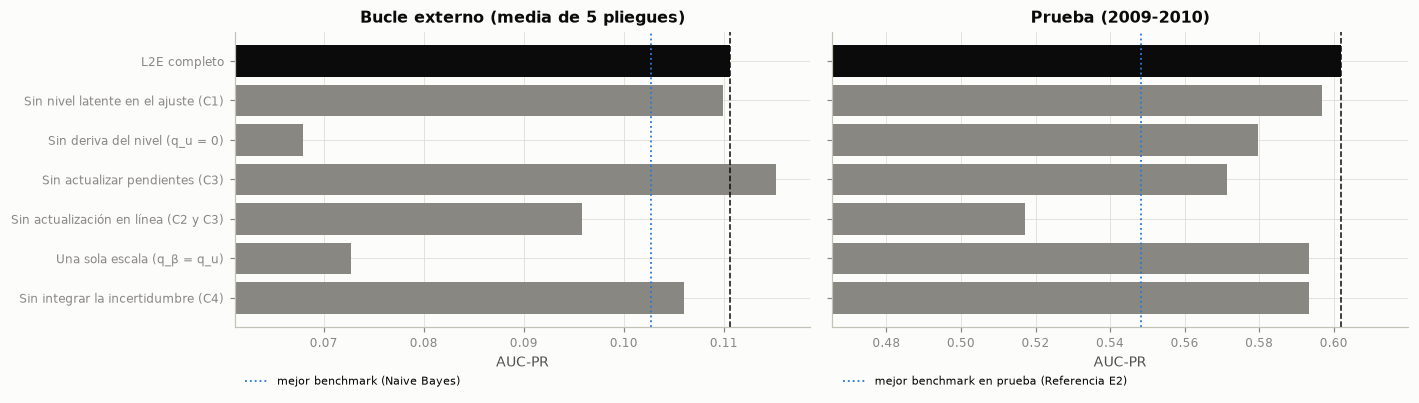

**Interpretación.** Retirar la actualización en línea (C2 y C3) baja el AUC-PR de 0,111 a 0,096 en el bucle externo y de 0,602 a 0,517 en la prueba; quitar la deriva del nivel lo deja en 0,068 y 0,580, y usar una sola escala en 0,073 y 0,593. Sin actualizar las pendientes, el bucle externo queda en 0,115 y la prueba en 0,571; sin nivel latente en el ajuste, en 0,110 y 0,597; y sin integrar la incertidumbre, en 0,106 y 0,593.

Lo anterior indica que el componente central es el nivel dinámico. En el bucle externo quedan por debajo del mejor benchmark las variantes sin actualización en línea, sin deriva del nivel y con una sola escala, y en la prueba, solo la variante sin actualización en línea. Sin actualización en línea el modelo pierde su ventaja en los dos escenarios. Sin deriva del nivel o con una sola escala, la caída se concentra en el último pliegue externo (0,121 y 0,121, frente a 0,317 del modelo completo), que contiene el cambio de régimen de 2009: con una sola tasa de deriva, la optimización tiene que elegir entre un nivel ágil con pendientes inestables o pendientes estables con un nivel rígido, que es la limitación de la logística dinámica clásica que motiva las dos escalas. La actualización de las pendientes aporta en la prueba, donde la deriva de concepto de 2009-2010 es mayor, pero no en el bucle externo, donde la variante sin pendientes es mejor que el modelo completo. El nivel latente en el ajuste y la integración de la incertidumbre tienen efectos pequeños, del orden de la variabilidad entre semillas del optimizador (sección {ref}`6.9 <sec-6-9>`).

En consecuencia, se decide mantener el modelo completo, que es el declarado antes de ejecutar los experimentos (sección {ref}`5.1 <sec-5-1>`). La variante sin actualizar las pendientes es la única que supera al L2E en el bucle externo, por 0,0045, y gana 3 de los 5 pliegues; esa diferencia no se distingue de cero (t corregida de Nadeau-Bengio, p = 0,855) y la prueba bayesiana de rangos con signo da una probabilidad de 0,59 de equivalencia práctica (ROPE de 0,01) frente a 0,21 de que la variante sea mejor. La ablación mide el aporte de cada componente, no elige el modelo, y con el bucle externo empatado no hay evidencia para retirar un componente que el diseño justifica con la deriva de concepto del entrenamiento; la prueba no interviene en esta decisión. Así mismo, se reporta de forma explícita que C1 y C4 son componentes de coherencia del modelo (el mismo paseo aleatorio en el ajuste y en la predicción, y probabilidades que reflejan la incertidumbre del nivel) más que fuentes de desempeño.

In [16]:
filas = []
for v in VARIANTES:
    ext_ = np.array([c["auc_pr"] for c in corr[v]])
    f_ = fin_l2e[v]
    filas.append({"Variante": NOMBRE_VARIANTE[v], "clave": v, "AUC-PR externo": ext_.mean(), "DE externo": ext_.std(ddof=1),
                  "AUC externo": np.mean([c["auc"] for c in corr[v]]), "AUC-PR prueba": f_["auc_pr"],
                  "AUC prueba": f_["auc"], "Brier prueba": f_["brier"]})
abl = pd.DataFrame(filas)
ref_abl = abl.iloc[0]
abl["Δ AUC-PR externo"] = abl["AUC-PR externo"] - ref_abl["AUC-PR externo"]
abl["Δ AUC-PR prueba"] = abl["AUC-PR prueba"] - ref_abl["AUC-PR prueba"]
tabla(abl.drop(columns="clave"), dec=4, indice=False)

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
yy = np.arange(len(abl))
for ax, col, tit in ((axs[0], "AUC-PR externo", "Bucle externo (media de 5 pliegues)"),
                     (axs[1], "AUC-PR prueba", "Prueba (2009-2010)")):
    colores = [TINTA if v == "l2e" else GRIS for v in abl["clave"]]
    ax.barh(yy, abl[col], color=colores)
    ax.axvline(ref_abl[col], color=TINTA, lw=1, ls="--")
    ax.set(title=tit, xlabel="AUC-PR")
    ax.set_xlim(abl[col].min() * 0.9, abl[col].max() * 1.03)
axs[0].set_yticks(yy, abl["Variante"])
axs[0].invert_yaxis()
mejor_b = pliegues_e3.merge(fin_ext.iloc[[0]][["modelo", "balanceo", "optimizador"]])["auc_pr"].mean()
axs[0].axvline(mejor_b, color=AZUL, lw=1.2, ls=":", label=f"mejor benchmark ({CORTO[MEJOR]})")
axs[1].axvline(ap_te[mejor_te], color=AZUL, lw=1.2, ls=":", label=f"mejor benchmark en prueba ({CORTO[mejor_te]})")
axs[0].legend(loc="upper left", bbox_to_anchor=(0, -0.13), fontsize=7.5)
axs[1].legend(loc="upper left", bbox_to_anchor=(0, -0.13), fontsize=7.5)
plt.tight_layout()
plt.show()

a = abl.set_index("clave")
para_guion("ablacion", abl)
# La única variante que supera al modelo completo en el bucle externo: ¿la diferencia se distingue del ruido?
ap_sp = np.array([c_["auc_pr"] for c_ in corr["sin_pendientes"]])
ap_l2 = np.array([c_["auc_pr"] for c_ in corr["l2e"]])
nb_sp = st4.t_nadeau_bengio(ap_sp, ap_l2, [c_["n_ent"] for c_ in corr["l2e"]], [c_["n_val"] for c_ in corr["l2e"]])
bay_sp = st4.rangos_signo_bayes(ap_sp, ap_l2, rope=0.01)
gana_sp = int((ap_sp > ap_l2).sum())
para_guion("ablacion_sp", {"dif": ap_sp.mean() - ap_l2.mean(), "gana": gana_sp, "p_nb": nb_sp["p"],
                           "p_rope": bay_sp["p_rope"], "p_mejor": bay_sp["p_a_mejor"]})
rango_ext = a["AUC-PR externo"].rank(ascending=False).astype(int)
rango_te = a["AUC-PR prueba"].rank(ascending=False).astype(int)
bajo_ext = [v for v in ("estatico", "sin_deriva_nivel", "escala_unica") if a.loc[v, "AUC-PR externo"] < mejor_b]
bajo_te = [v for v in ("estatico", "sin_deriva_nivel", "escala_unica") if a.loc[v, "AUC-PR prueba"] < ap_te[mejor_te]]
NV = {"estatico": "sin actualización en línea", "sin_deriva_nivel": "sin deriva del nivel",
      "escala_unica": "con una sola escala"}
interpretar(
    f"Retirar la actualización en línea (C2 y C3) baja el AUC-PR de {num(a.loc['l2e', 'AUC-PR externo'], 3)} a "
    f"{num(a.loc['estatico', 'AUC-PR externo'], 3)} en el bucle externo y de {num(a.loc['l2e', 'AUC-PR prueba'], 3)} a "
    f"{num(a.loc['estatico', 'AUC-PR prueba'], 3)} en la prueba; quitar la deriva del nivel lo deja en "
    f"{num(a.loc['sin_deriva_nivel', 'AUC-PR externo'], 3)} y {num(a.loc['sin_deriva_nivel', 'AUC-PR prueba'], 3)}, y "
    f"usar una sola escala en {num(a.loc['escala_unica', 'AUC-PR externo'], 3)} y "
    f"{num(a.loc['escala_unica', 'AUC-PR prueba'], 3)}. Sin actualizar las pendientes, el bucle externo queda en "
    f"{num(a.loc['sin_pendientes', 'AUC-PR externo'], 3)} y la prueba en {num(a.loc['sin_pendientes', 'AUC-PR prueba'], 3)}; "
    f"sin nivel latente en el ajuste, en {num(a.loc['sin_nivel_latente', 'AUC-PR externo'], 3)} y "
    f"{num(a.loc['sin_nivel_latente', 'AUC-PR prueba'], 3)}; y sin integrar la incertidumbre, en "
    f"{num(a.loc['sin_incertidumbre', 'AUC-PR externo'], 3)} y {num(a.loc['sin_incertidumbre', 'AUC-PR prueba'], 3)}.",
    conectar("Lo anterior indica que", "El componente central es el nivel dinámico. En el bucle externo quedan por "
             f"debajo del mejor benchmark las variantes {enumerar([NV[v] for v in bajo_ext]) or 'ninguna'}, y en la "
             f"prueba, {'solo la variante ' if len(bajo_te) == 1 else 'las variantes '}"
             f"{enumerar([NV[v] for v in bajo_te]) or 'ninguna'}. Sin actualización en línea el modelo pierde su "
             "ventaja en los dos escenarios. Sin deriva del nivel o con una sola escala, la caída se concentra en el "
             f"último pliegue externo ({num(corr['sin_deriva_nivel'][4]['auc_pr'], 3)} y "
             f"{num(corr['escala_unica'][4]['auc_pr'], 3)}, frente a {num(corr['l2e'][4]['auc_pr'], 3)} del modelo "
             "completo), que contiene el cambio de régimen de 2009: con una sola tasa de deriva, la optimización tiene "
             "que elegir entre un nivel ágil con pendientes inestables o pendientes estables con un nivel rígido, que "
             "es la limitación de la logística dinámica clásica que motiva las dos escalas. La actualización de las pendientes aporta en la prueba, donde la "
             "deriva de concepto de 2009-2010 es mayor, pero no en el bucle externo, donde la variante sin pendientes "
             f"es {'mejor' if a.loc['sin_pendientes', 'AUC-PR externo'] > a.loc['l2e', 'AUC-PR externo'] else 'peor'} "
             "que el modelo completo. El nivel latente en el ajuste y la integración de la incertidumbre tienen efectos "
             "pequeños, del orden de la variabilidad entre semillas del optimizador (sección 6.9)."),
    conectar("En consecuencia, se decide", "Mantener el modelo completo, que es el declarado antes de ejecutar los "
             "experimentos (sección 5.1). La variante sin actualizar las pendientes es la única que supera al L2E en el "
             f"bucle externo, por {num(a.loc['sin_pendientes', 'AUC-PR externo'] - a.loc['l2e', 'AUC-PR externo'], 4)}, "
             f"y gana {gana_sp} de los {cfg.K_EXTERNO} pliegues; esa diferencia no se distingue de cero (t corregida de "
             f"Nadeau-Bengio, p = {num(nb_sp['p'], 3)}) y la prueba bayesiana de rangos con signo da una probabilidad de "
             f"{num(bay_sp['p_rope'], 2)} de equivalencia práctica (ROPE de 0,01) frente a {num(bay_sp['p_a_mejor'], 2)} "
             "de que la variante sea mejor. La ablación mide el aporte de cada componente, no elige el modelo, y con el "
             "bucle externo empatado no hay evidencia para retirar un componente que el diseño justifica con la deriva "
             "de concepto del entrenamiento; la prueba no interviene en esta decisión. Así mismo, se reporta de forma "
             "explícita que C1 y C4 son componentes de coherencia del modelo (el mismo paseo aleatorio en el ajuste y en "
             "la predicción, y probabilidades que reflejan la incertidumbre del nivel) más que fuentes de desempeño."))